20/11/2026

LFP Peth and delta investigation for the poster

In [1]:
#libraries importation 
%matplotlib widget
%load_ext autoreload
%autoreload 2
import numpy as np
import re
import ast
import fmatoolbox as fma
import scipy.stats as spst
import pathlib
from format_intervals import format_intervals
from stim_times_extracting import extract_stim_start_corrected
froot = pathlib.Path().cwd()
batch_file = froot / 'sessions.batch'

In [2]:
#Parameters to verify on each session : accel_channels, interval, start_reccord_sec, start, stop

record_path='/mnt/hubel-data-103/Ana/Working_zone/ISA detection figures/'
accel_channels = [128, 129, 130]
FR_channel = [141]
stim_channel = [137]
#portion of visualisation 
interval = [0,7198] 
start_acc = interval[0]
stop_acc  = interval[1]
# If no MATLAB session is available, you can define these values manually:
# start_sec_decay = start_reccord_sec      --> Time offset to apply
# time_end_reccord_oe = maximum valid Open Ephys timestamp

# Otherwise, if a MATLAB session is available (as in the original pipeline):
# L_start_stop = eventIntervals(R)
# start = L_start_stop(1)
# stop = L_start_stop(2)
# decay_from_open_ephys = seconds(start_reccord_sec - start)
# start_sec_decay = decay_from_open_ephys + start
# time_end_reccord_oe = stop - start_sec_decay

#STANDALONE VERSION WITHOUT MATLAB FILE 

start = 0      # Session start time (s)
stop = 7198   # Session stop time (s)

# To be adjusted: cumulative session time at the start of the Open Ephys replay (s)
# (i.e., the Start Time parameter in the File Reader)
start_reccord_sec = 1750

# Time offset between the Open Ephys recording and the cumulative session timeline (s)
decay_from_open_ephys = start_reccord_sec - start

# Maximum valid timestamp in the Open Ephys detection lists
time_end_reccord_oe = stop_acc - start_reccord_sec

In [3]:
#files reading 

# session = fma.data.readBatchFile(batch_file)[0][58]
session = '/mnt/hubel-data-149/Photon_Rat014/Rat014_2026-07-15_13-31-42/Rat014_2026-07-15_13-31-42.xml'
stim_file='/mnt/hubel-data-149/Photon_Rat014/Rat014_2026-07-15_13-31-42/stim_times.txt'
print(session)
print(stim_file)

R = fma.regions.regions(session)
stim_txt= open(stim_file, "r", encoding="utf-8").read()
print(stim_txt)

/mnt/hubel-data-149/Photon_Rat014/Rat014_2026-07-15_13-31-42/Rat014_2026-07-15_13-31-42.xml
/mnt/hubel-data-149/Photon_Rat014/Rat014_2026-07-15_13-31-42/stim_times.txt


/home/ana/uvEnvs/analyseOE_12/lib/python3.12/site-packages/fmatoolbox/data.py:145: UserWarning: loadtxt: input contained no data: "/mnt/hubel-data-149/Photon_Rat014/Rat014_2026-07-15_13-31-42/Rat014_2026-07-15_13-31-42.clu.8"
  clu = {c: np.loadtxt(clu_files[c],comments='%',delimiter=',') for c in clu_files}


# stim_times (s): column 1 = start, column 2 = end
# channel: 137
# parameters: k_low=5 k_high=15 max_gap=0.02 min_dur=0.04
308.214002	308.312652
457.713953	457.812503
467.821853	467.970453
502.113853	502.212403
512.421903	512.520503
523.511703	523.610403
1112.581706	1112.680306
1182.348107	1182.446657
1292.678457	1292.777007
1413.502508	1413.601108
4984.706978	4984.805628
5056.849078	5056.947728
5080.158628	5080.307278
5104.806678	5104.955378
5137.813929	5137.962579
5202.364079	5202.462729
5227.629029	5227.727729
5241.508479	5241.607129
5420.905030	5421.003680
5529.335331	5529.433981
5543.256231	5543.354881
5554.782981	5554.881681
5563.910831	5564.009581
5573.878831	5574.027481
6451.765936	6451.864536
6489.438736	6489.537386
7113.955690	7114.104340
7217.505640	7217.604290
7294.555041	7294.803741
7337.351391	7337.450091
8096.513945	8096.612545
8157.512745	8157.611395
8203.797446	8203.946146
8250.444746	8250.593446
8286.358496	8286.457146
8295.870496	8295.969146
8320.975146	8321.073796


In [4]:
def read_stim_times(text):
    """Return an (n, 2) array [start, end] from a stim_times text file.
    Lines starting with '#' and lines that are not two numbers (e.g. '...') are ignored."""
    rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        parts = line.split()
        try:
            rows.append([float(parts[0]), float(parts[1])])
        except (ValueError, IndexError):
            continue
    return np.array(rows, dtype=float)

stim = read_stim_times(stim_txt)
print(stim.shape)
print(stim[:5])

intervals_stim=np.array([[stim[i][0]-15,stim[i][0]+15]for i in range (0,len(stim))])
print(intervals_stim)

(40, 2)
[[308.214002 308.312652]
 [457.713953 457.812503]
 [467.821853 467.970453]
 [502.113853 502.212403]
 [512.421903 512.520503]]
[[ 293.214002  323.214002]
 [ 442.713953  472.713953]
 [ 452.821853  482.821853]
 [ 487.113853  517.113853]
 [ 497.421903  527.421903]
 [ 508.511703  538.511703]
 [1097.581706 1127.581706]
 [1167.348107 1197.348107]
 [1277.678457 1307.678457]
 [1398.502508 1428.502508]
 [4969.706978 4999.706978]
 [5041.849078 5071.849078]
 [5065.158628 5095.158628]
 [5089.806678 5119.806678]
 [5122.813929 5152.813929]
 [5187.364079 5217.364079]
 [5212.629029 5242.629029]
 [5226.508479 5256.508479]
 [5405.90503  5435.90503 ]
 [5514.335331 5544.335331]
 [5528.256231 5558.256231]
 [5539.782981 5569.782981]
 [5548.910831 5578.910831]
 [5558.878831 5588.878831]
 [6436.765936 6466.765936]
 [6474.438736 6504.438736]
 [7098.95569  7128.95569 ]
 [7202.50564  7232.50564 ]
 [7279.555041 7309.555041]
 [7322.351391 7352.351391]
 [8081.513945 8111.513945]
 [8142.512745 8172.512745]
 [

In [5]:
# Display cumulative session time boundaries for the theoric file
epoch = R.eventIntervals()
print(epoch)
start = epoch[0,0]
stop = epoch[0,1]
channels_pfc=[i for i in range (96,128)]
print(len(channels_pfc))
print(channels_pfc)

[[   0.     9001.4848]]
32
[96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127]


(array([[-535,  424, -108, ..., -486, -517, -722],
       [-417,  502,   10, ..., -407, -496, -681],
       [-352,  518,   85, ..., -438, -477, -676],
       ...,
       [-566, -236, -274, ..., -294, -207, -484],
       [-593, -169, -294, ..., -375, -256, -598],
       [-674, -352, -389, ..., -355, -241, -601]],
      shape=(37500, 32), dtype=int16), array([293.214002  , 293.21480202, 293.21560204, ..., 323.21240196,
       323.21320198, 323.214002  ], shape=(37500,)))


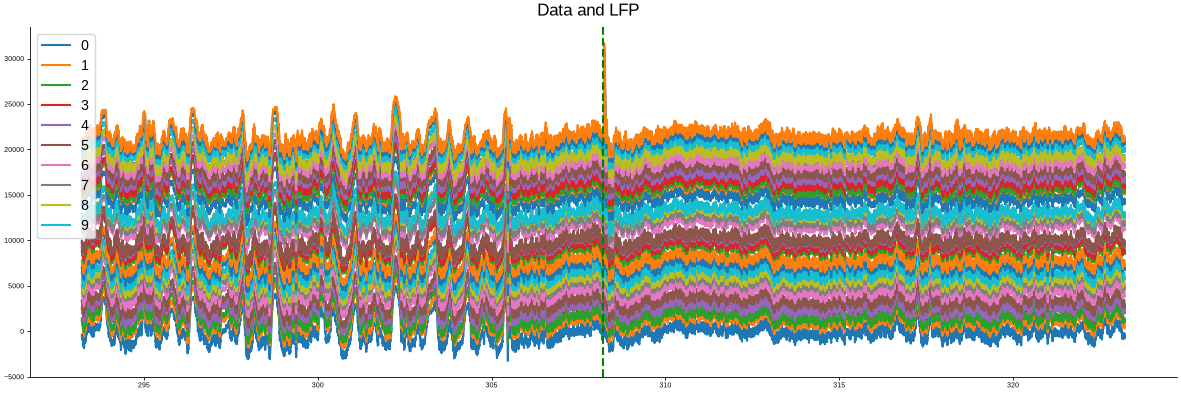

In [6]:
#test_dat=fma.data.loadWideband(session,channels=channels_pfc, intervals = intervals_stim[0])
#print(test_dat)
test_lfp=fma.data.loadWideband(session,channels=channels_pfc, intervals = intervals_stim[0], lfp=True)
print(test_lfp)
#ch_dat=[np.column_stack((test_dat[1],test_dat[0].T[i])) for i in range (0,32)]

fig, ax=fma.plotting.figure(size=(30,10),title=f'Data and LFP ')
offset=0
for i in range (0,32):
    ch_lfp=np.column_stack((test_lfp[1],test_lfp[0].T[i]+offset))
    #fma.plotting.plotXY(ch_dat[i],label='Dat')
    if i<10:
        fma.plotting.plotXY(ch_lfp, label=f'{i}')
    else:
        fma.plotting.plotXY(ch_lfp)
    offset+=700
ax.axvline(stim[0][0],color='g',ls='--')
ax.legend();

In [7]:
lfp_data=fma.data.loadWideband(session,channels=channels_pfc, intervals = intervals_stim, lfp=True)
print(lfp_data)
n_stims = len(stim)            # 40
n_samples = 37500              # 30 s * 1250 Hz
n_channels = len(channels_pfc) # 32

lfp = lfp_data[0].reshape(n_stims, n_samples, n_channels)   # (40, 32, 37500, ): stim, channel, sample, 
t_abs = lfp_data[1].reshape(n_stims, n_samples)             # (40, 37500): absolute time of each sample
t_rel = t_abs - stim[:, 0][:, None]                         # time relative to each stim

# check: every excerpt must start at the beginning of its interval (stim start - 15 s)
assert np.allclose(t_abs[:, 0], intervals_stim[:, 0], atol=2 / 1250), 'excerpts are not in stim order'
print(lfp.shape)
print(lfp)
print()
print(t_rel.shape)
print(t_rel)


(array([[-535,  424, -108, ..., -486, -517, -722],
       [-417,  502,   10, ..., -407, -496, -681],
       [-352,  518,   85, ..., -438, -477, -676],
       ...,
       [ 770, 1318, 1146, ...,  945, 1018,  720],
       [ 747, 1209, 1075, ...,  888,  960,  696],
       [ 792, 1170, 1121, ...,  841,  960,  644]],
      shape=(1500000, 32), dtype=int16), array([ 293.214002  ,  293.21480202,  293.21560204, ..., 8436.49109696,
       8436.49189698, 8436.492697  ], shape=(1500000,)))
(40, 37500, 32)
[[[ -535   424  -108 ...  -486  -517  -722]
  [ -417   502    10 ...  -407  -496  -681]
  [ -352   518    85 ...  -438  -477  -676]
  ...
  [ -566  -236  -274 ...  -294  -207  -484]
  [ -593  -169  -294 ...  -375  -256  -598]
  [ -674  -352  -389 ...  -355  -241  -601]]

 [[-1754  -978 -1360 ... -1381 -1274 -1726]
  [-1826 -1074 -1448 ... -1482 -1489 -1828]
  [-1892 -1087 -1544 ... -1547 -1585 -1951]
  ...
  [  782  1134  1113 ...   598   691   382]
  [  711  1111  1025 ...   492   584   291]
  

In [8]:
spikes_pfc=R.spikes(regs='pfc',when=[interval for interval in intervals_stim])
spikes_pfc_times=[spikes_pfc[:,0]]
print(spikes_pfc)
print(spikes_pfc_times)


[[ 293.22615  209.     ]
 [ 293.25365  179.     ]
 [ 293.2627   161.     ]
 ...
 [8436.4621   148.     ]
 [8436.4821   159.     ]
 [8436.48215  143.     ]]
[array([ 293.22615,  293.25365,  293.2627 , ..., 8436.4621 , 8436.4821 ,
       8436.48215], shape=(153753,))]


In [9]:
PETH_stim_pfc=fma.analysis.PETH(spikes_pfc_times,stim,bin=0.01,limits=[-15,15],step=5,smooth=None)
#trac_PETH_pfc=np.column_stack((PETH_stim_pfc[1],PETH_stim_pfc[2]))

KeyboardInterrupt: 

In [18]:
bin=0.01
limits=[-15,15]
step=5
for cha in range (0,len(channels_pfc)) : 
    # mat, t, m = fma.analysis.PETH(lfp_data[0],stim[:][0],bin=bin,limits=limits,step=step,smooth=3)
    # trac_PETH_pfc=np.column_stack((t,m))
    mat, t, m =fma.analysis.PETH(spike_times_pfc,stim_times,bin=bin,limits=limits,step=step,smooth=None)
    fig, ax = fma.plotting.figure(size=(43,15), title=f'channel{cha}')
    # ax.axvline(0,ls='--',color='gray')
    # fma.plotting.plotXY(trac_PETH_pfc,color='blue')
    fma.plotting.plotRaster(mat, compact=True,  color='#246DC6')


NameError: name 'spike_times_pfc' is not defined

NameError: name 'trac_PETH_pfc' is not defined

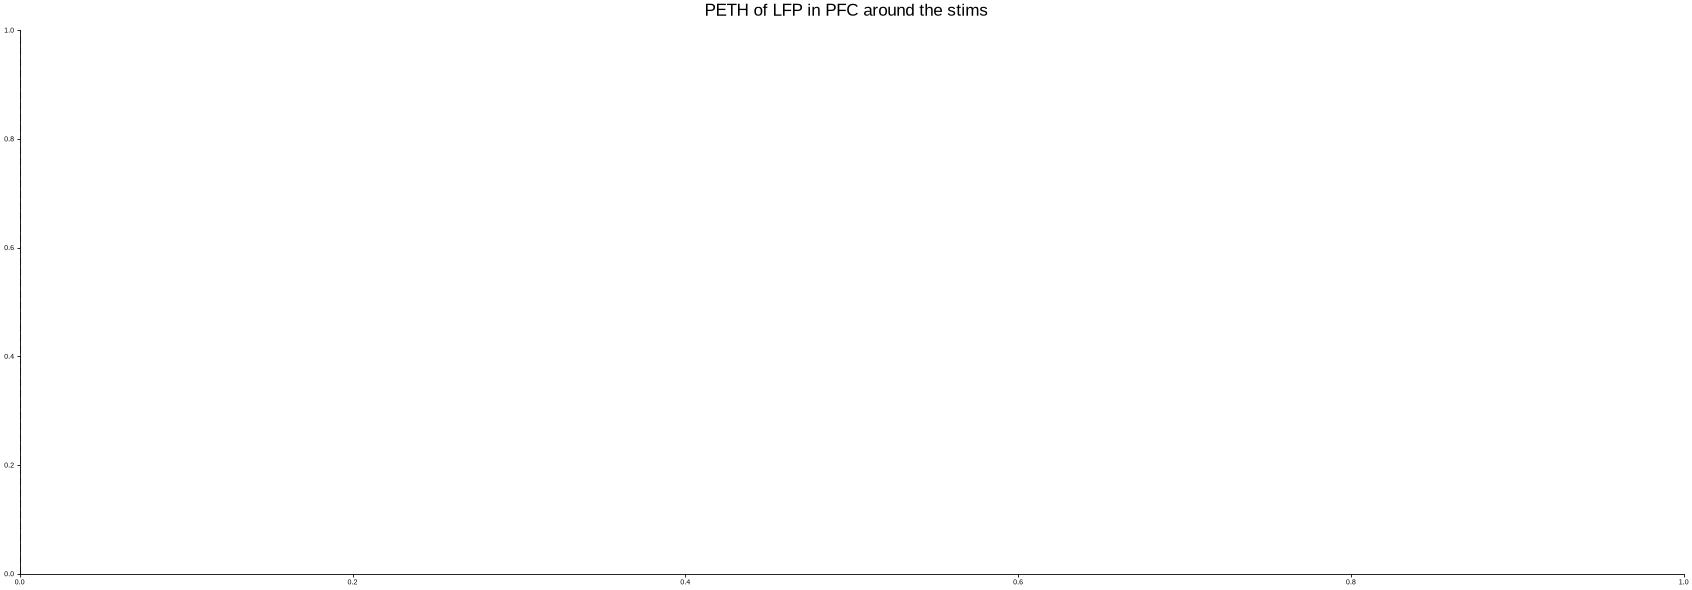

In [19]:
fig, ax = fma.plotting.figure(size=(43,15), title='PETH of LFP in PFC around the stims')
ax.axvline(0,ls='--',color='gray')
#ax[0].axvline(0.1,ls='--',color='gray')
fma.plotting.plotXY(trac_PETH_pfc,color='blue')

ax.legend();

In [20]:
spikes_pfc=[]
for interval in intervals_stim :
    spikes=R.spikes(regs='pfc',when=interval)
    spikes_pfc.append(spikes)

(293.214002, 323.214002)

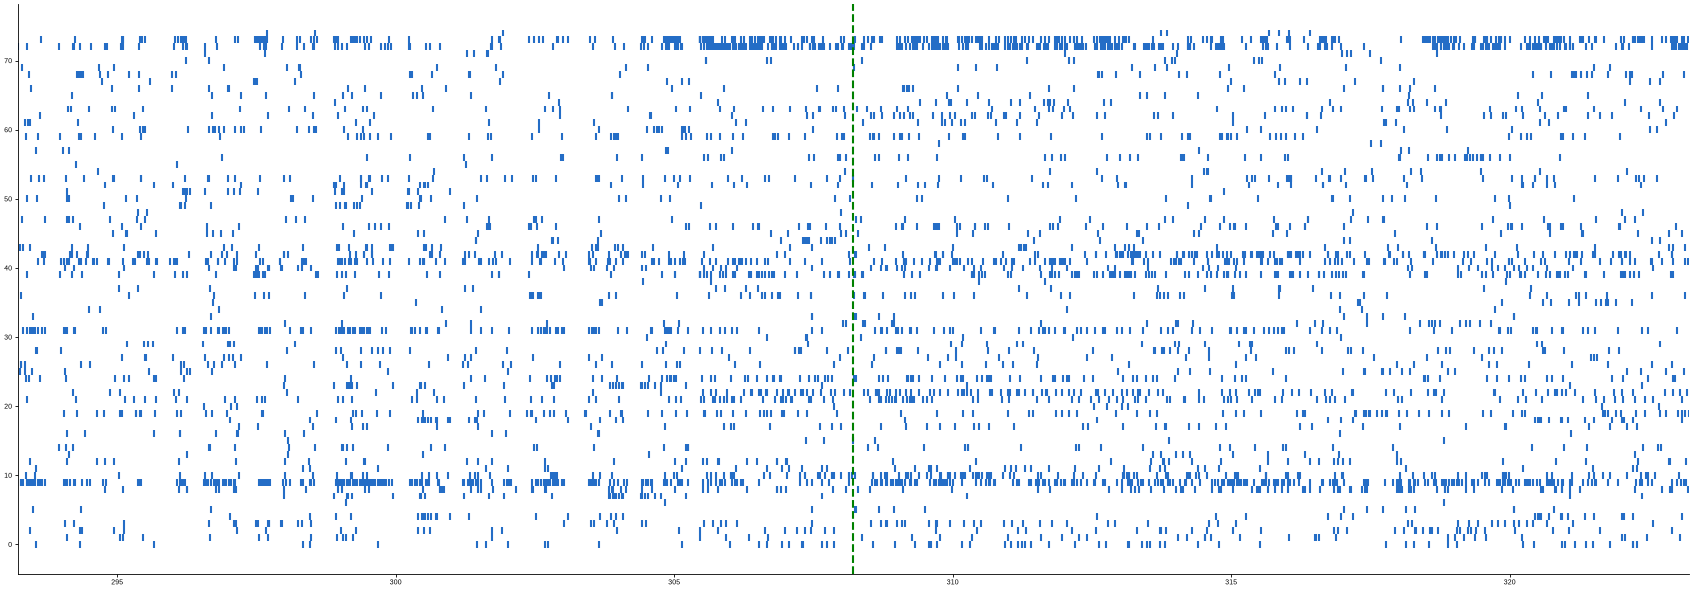

In [21]:
fig, ax = fma.plotting.figure(size=(43,15))
ax = np.atleast_1d(ax).ravel()[0]
spikes_raster=[el for el in spikes_pfc[0]]
fma.plotting.plotRaster(spikes_raster, compact=True,  color='#246DC6')
ax.axvline(stim[0][0], linestyle='--',color='g')
ax.set_xlim(intervals_stim[0])

/tmp/ipykernel_1345036/3920805587.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend();


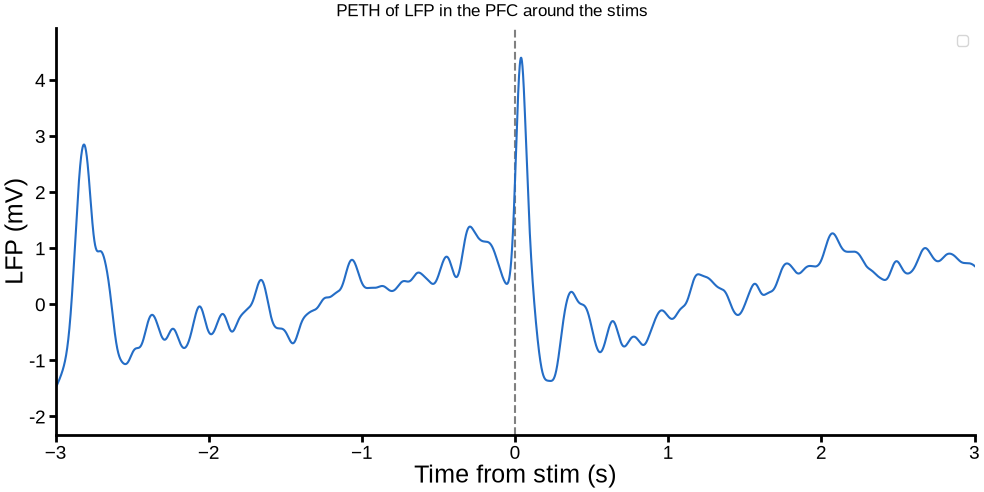

In [22]:
from scipy.ndimage import gaussian_filter1d
from matplotlib.ticker import FuncFormatter

SCALE = 1000    # displayed tick = real value / SCALE


PETH_homemade = test_lfp[0].sum(axis=1)/32
t = test_lfp[1] - stim[0][0]                      # time relative to the stim

# smoothing: width given in seconds, converted to samples
SMOOTH_SEC = 0.03                                 # standard deviation of the gaussian (s)
dt = np.median(np.diff(t))                        # sampling period (s)
PETH_smooth = gaussian_filter1d(PETH_homemade, sigma=SMOOTH_SEC / dt)

trac_PETH_pfc_homemade = np.column_stack((t, PETH_smooth))

fig, ax = fma.plotting.figure(size=(10,5), title='PETH of LFP in the PFC around the stims',format='poster')
ax.axvline(0,ls='--',color='gray')
#ax[0].axvline(0.1,ls='--',color='gray')
fma.plotting.plotXY(trac_PETH_pfc_homemade,color='#246DC6')
ax.set_xlim([-3,3])
ax.set_xlabel('Time from stim (s)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / SCALE:g}'))
ax.set_ylabel('LFP (mV)')     # adapt the label to the displayed unit
ax.legend();

40 stim(s) averaged, 0 skipped


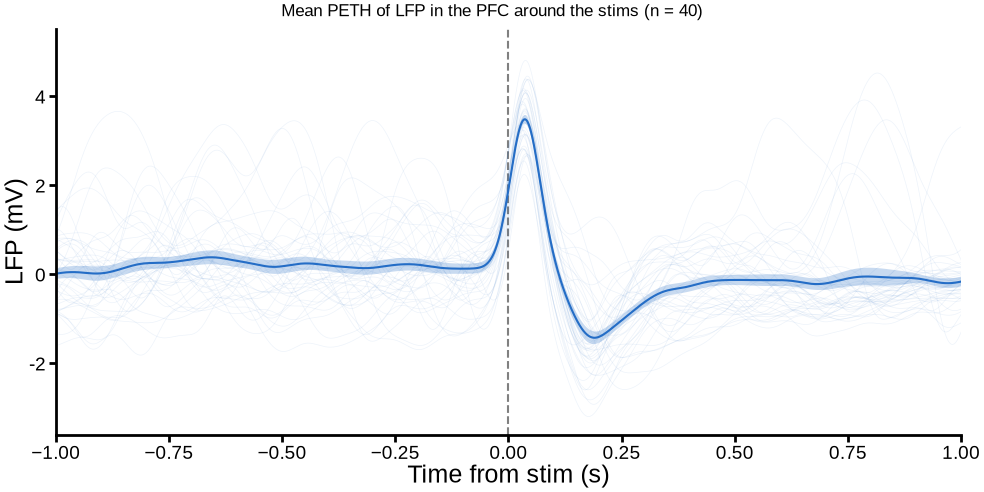

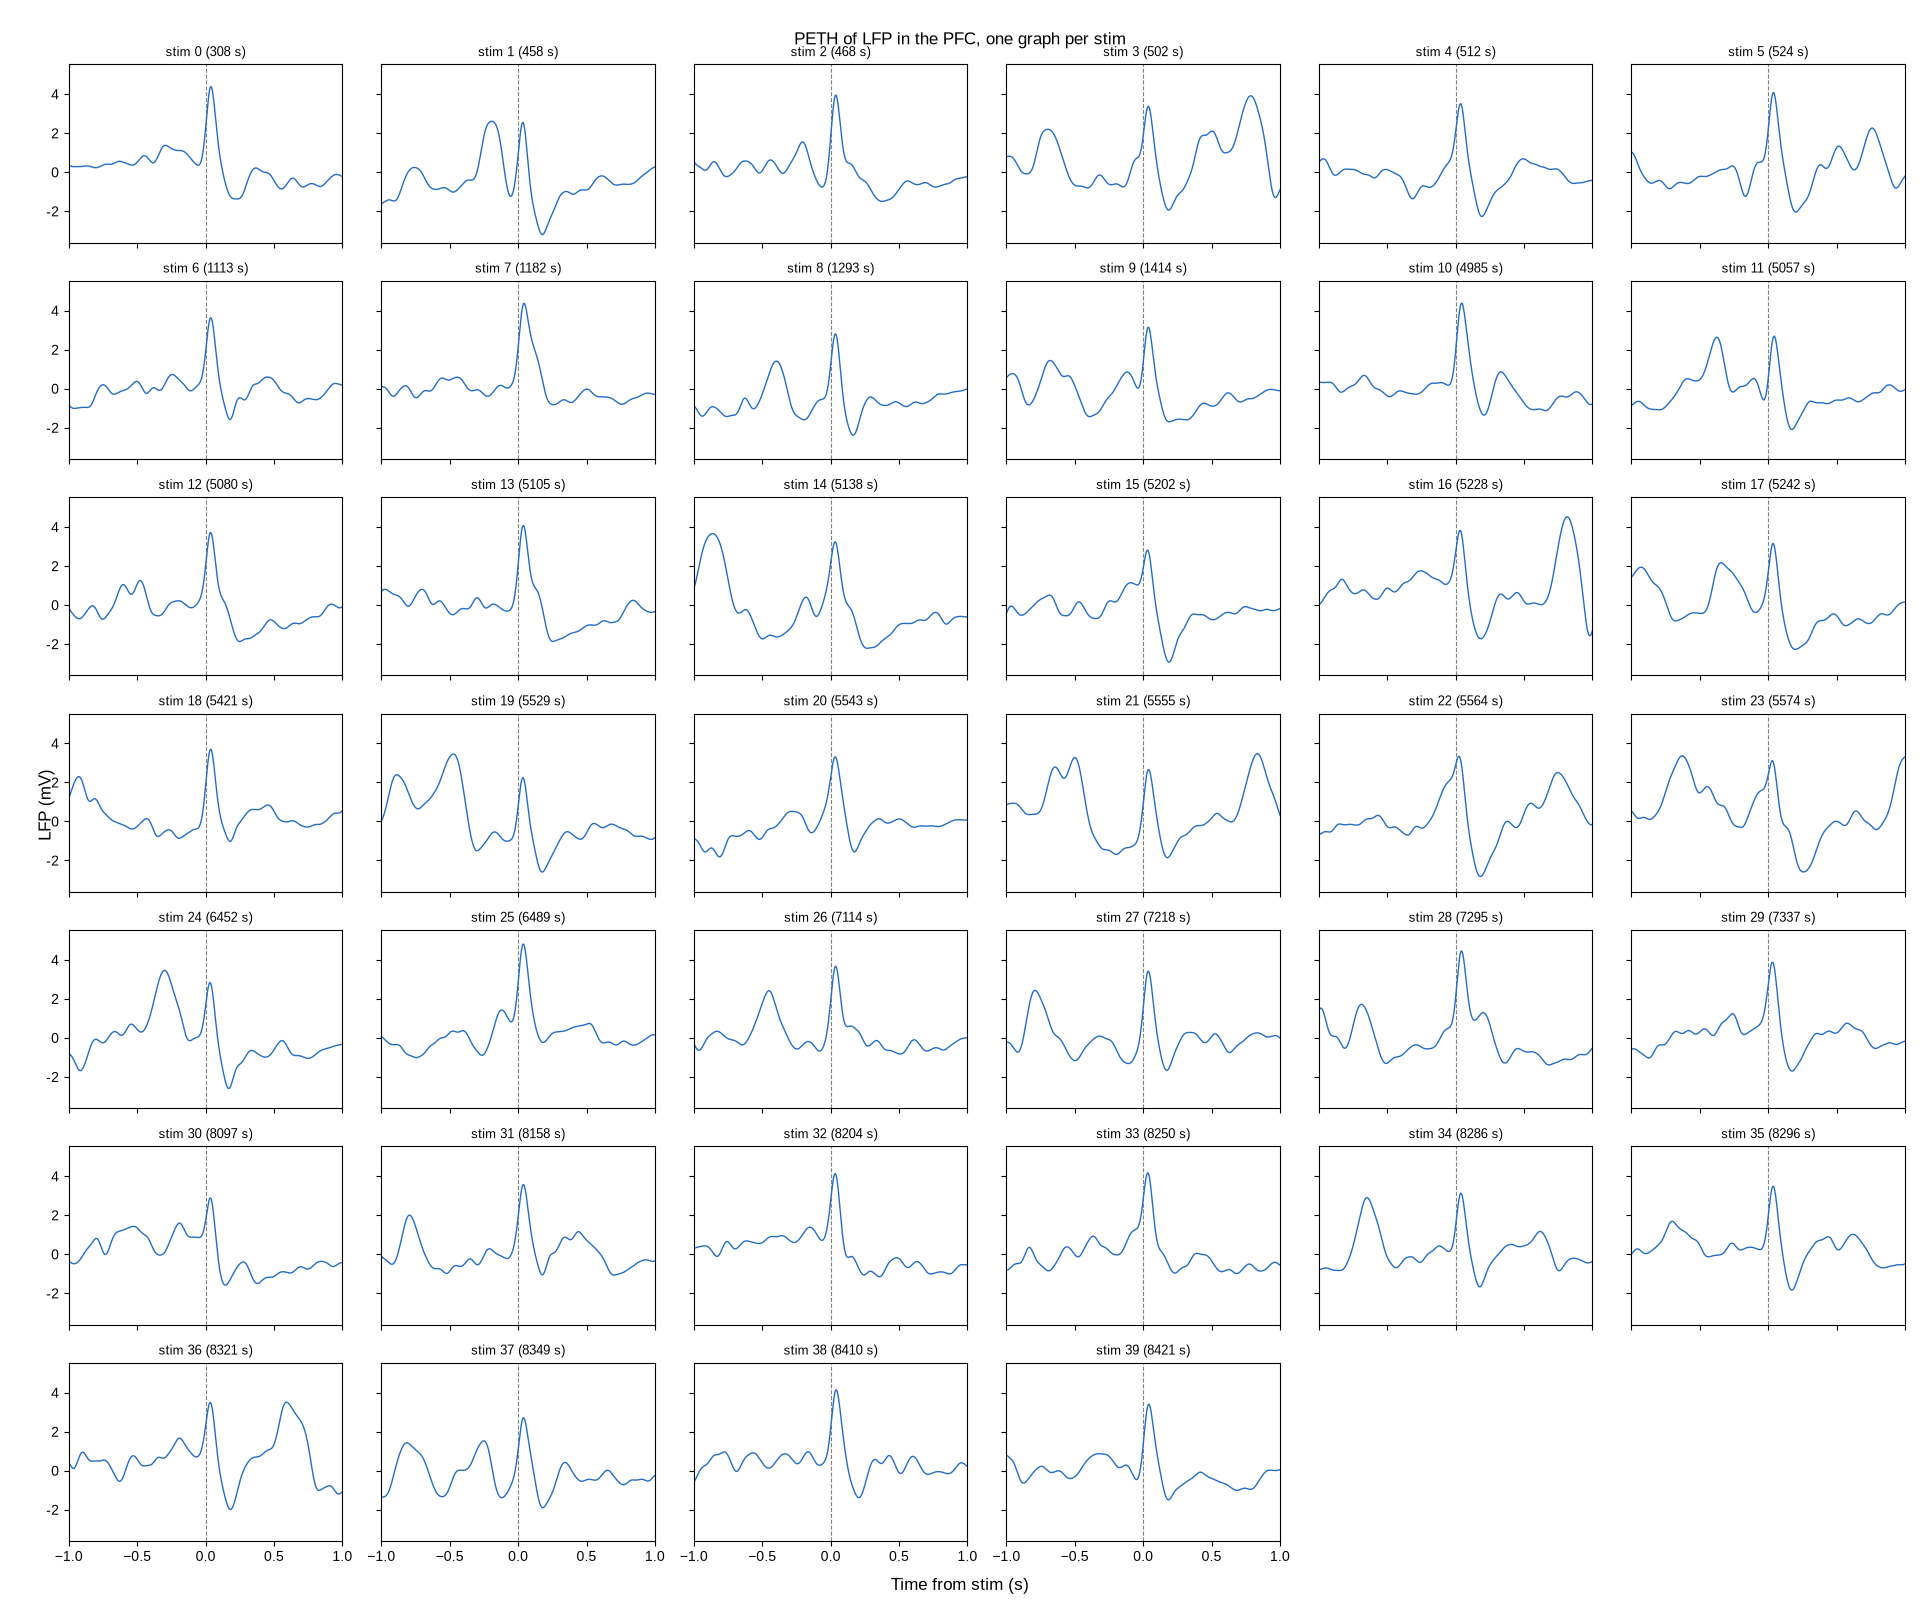

In [23]:
# all stim: same figure, averaged over every stim
N_CH = len(channels_pfc)
t_common = np.arange(-15, 15, dt)                 # common time axis (intervals_stim = stim start +/- 15 s)

all_peth, skipped, kept = [], [], []              # kept = indices of the stims actually loaded
for k, (interval_k, stim_k) in enumerate(zip(intervals_stim, stim[:, 0])):
    try:
        lfp_k = fma.data.loadWideband(session, channels=channels_pfc, intervals=interval_k, lfp=True)
    except Exception as err:                      # e.g. stim too close to the end of the recording
        skipped.append((k, f'{type(err).__name__}: {err}'))
        continue
    sig_k = gaussian_filter1d(lfp_k[0].sum(axis=1) / N_CH, sigma=SMOOTH_SEC / dt)
    t_k = lfp_k[1] - stim_k                       # time relative to this stim
    all_peth.append(np.interp(t_common, t_k, sig_k, left=np.nan, right=np.nan))   # same time axis for all stims
    kept.append(k)

all_peth = np.array(all_peth)                     # shape (n_stims, n_time)
mean_peth = np.nanmean(all_peth, axis=0)
sem_peth = np.nanstd(all_peth, axis=0) / np.sqrt(np.sum(np.isfinite(all_peth), axis=0))
print(f'{len(all_peth)} stim(s) averaged, {len(skipped)} skipped')
for k, reason in skipped:
    print(f'SKIPPED stim {k}: {reason}')

# figure 1: mean over every stim
fig, ax = fma.plotting.figure(size=(10,5), title=f'Mean PETH of LFP in the PFC around the stims (n = {len(all_peth)})', format='poster')
ax.axvline(0, ls='--', color='gray')
for trace in all_peth:                            # one thin trace per stim
    ax.plot(t_common, trace, color='#246DC6', alpha=0.08, linewidth=0.5)
ax.fill_between(t_common, mean_peth - sem_peth, mean_peth + sem_peth, color='#246DC6', alpha=0.25, linewidth=0)
fma.plotting.plotXY(np.column_stack((t_common, mean_peth)), color='#246DC6')
ax.set_xlim([-1, 1])
ax.set_xlabel('Time from stim (s)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / SCALE:g}'))
ax.set_ylabel('LFP (mV)')

# figure 2: one graph per stim (grid of subplots, same time axis and same y scale for all)
import math
import matplotlib.pyplot as plt

N_COLS = 6
n_stims = len(all_peth)
n_rows = math.ceil(n_stims / N_COLS)

fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.2 * N_COLS, 2.3 * n_rows), sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()
for ax_, k_, trace in zip(axes, kept, all_peth):
    ax_.axvline(0, ls='--', color='gray', linewidth=0.8)
    ax_.plot(t_common, trace, color='#246DC6', linewidth=1)
    ax_.set_title(f'stim {k_} ({stim[k_, 0]:.0f} s)', fontsize=9)
    ax_.set_xlim([-1, 1])
    ax_.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / SCALE:g}'))
for ax_ in axes[n_stims:]:                        # hide the unused panels of the last row
    ax_.set_visible(False)
fig.supxlabel('Time from stim (s)')
fig.supylabel('LFP (mV)')
fig.suptitle('PETH of LFP in the PFC, one graph per stim')
fig.tight_layout()



In [25]:
import matplotlib.pyplot as plt

WIN = (-3, 3)                                     # window around the stim (s), same as the LFP figure

spike_times = spikes_pfc[:, 0]
spike_units = spikes_pfc[:, 1]
unit_ids = np.unique(spike_units)
stim_starts = stim[:, 0]

# for each unit: spike times relative to each stim, all the stims superimposed
rel_by_unit = []
for u_ in unit_ids:
    st_ = np.sort(spike_times[spike_units == u_])
    rel_ = []
    for s_ in stim_starts:
        i0, i1 = np.searchsorted(st_, [s_ + WIN[0], s_ + WIN[1]])
        rel_.append(st_[i0:i1] - s_)
    rel_by_unit.append(np.concatenate(rel_))

TypeError: list indices must be integers or slices, not tuple

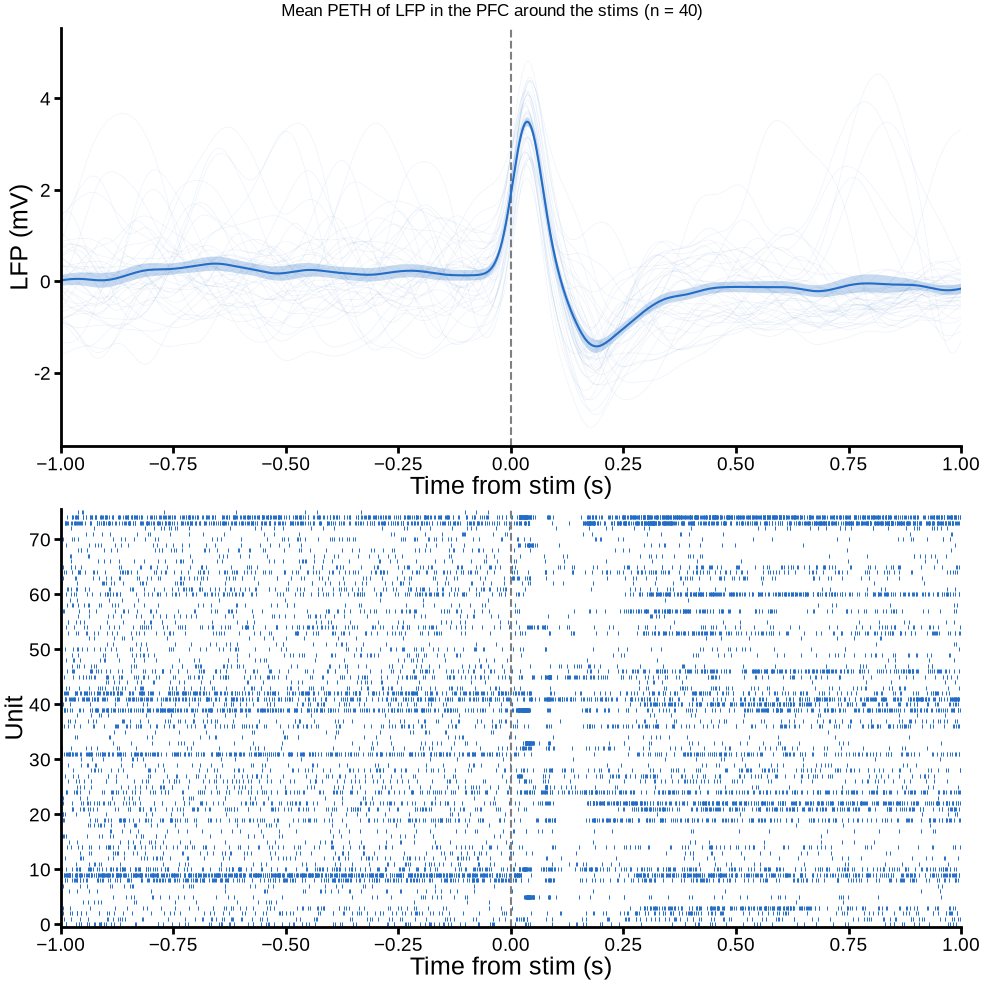

In [28]:
fig, ax = fma.plotting.figure(n=(2,1), size=(10,10), title=f'Mean PETH of LFP in the PFC around the stims (n = {len(all_peth)})', format='poster')
ax[0].axvline(0, ls='--', color='gray')
ax[1].axvline(stim[0][0], ls='--', color='gray')
for trace in all_peth:                            # one thin trace per stim
    ax[0].plot(t_common, trace, color='#246DC6', alpha=0.08, linewidth=0.5)
ax[0].fill_between(t_common, mean_peth - sem_peth, mean_peth + sem_peth, color='#246DC6', alpha=0.25, linewidth=0)
fma.plotting.plotXY(np.column_stack((t_common, mean_peth)), ax=ax[0], color='#246DC6')
ax[0].set_xlim([-1, 1])
ax[0].set_xlabel('Time from stim (s)')
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / SCALE:g}'))
ax[0].set_ylabel('LFP (mV)')

ax[1].eventplot(rel_by_unit, colors='#246DC6', linelengths=0.8, linewidths=0.7)   # one row per unit
ax[1].axvline(0, ls='--', color='gray')
ax[1].set_xlim([-1,1])
ax[1].set_ylim(-0.5, len(unit_ids) - 0.5)
ax[1].set_xlabel('Time from stim (s)')
ax[1].set_ylabel('Unit')
fma.plotting.saveFigure(fig, record_path+'PETH_LFP_and_scatter', 'png')

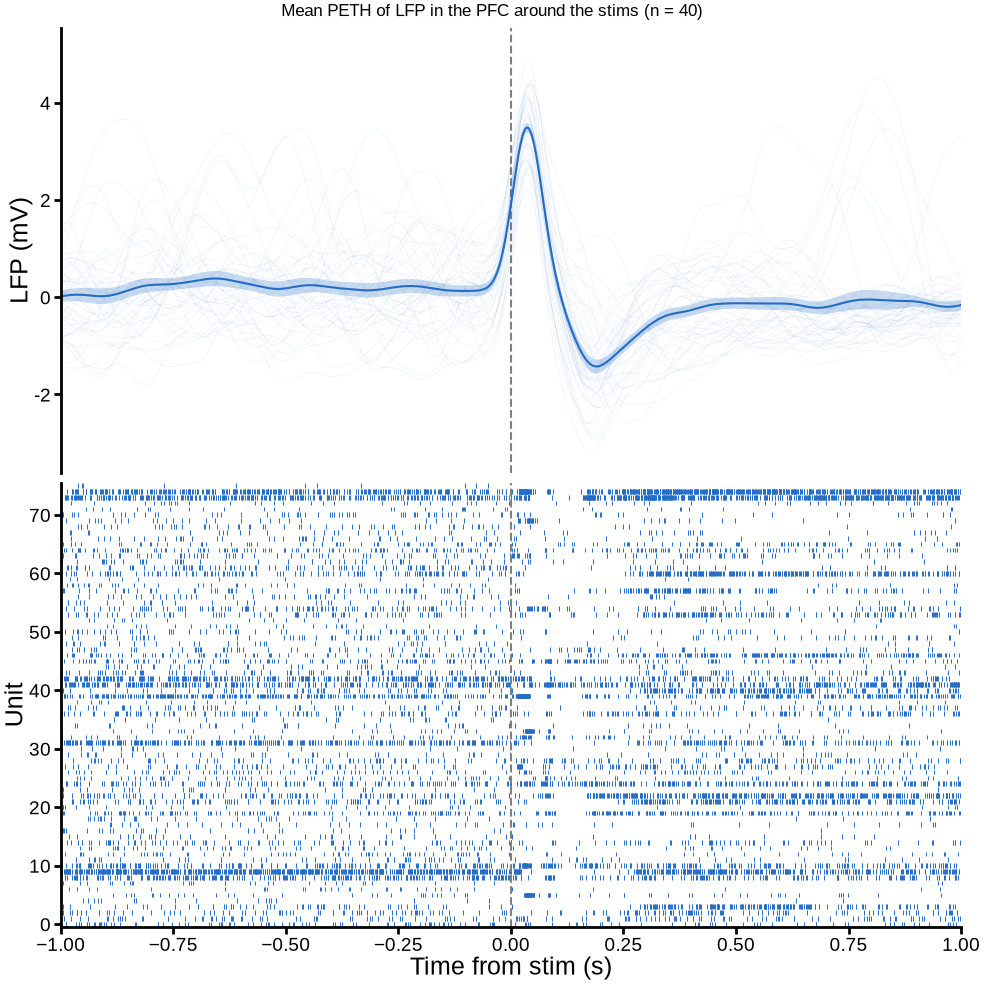

In [31]:
fig, ax = fma.plotting.figure(n=(2,1), size=(10,10), title=f'Mean PETH of LFP in the PFC around the stims (n = {len(all_peth)})', format='poster')

# top: mean LFP PETH
ax[0].axvline(0, ls='--', color='gray')
for trace in all_peth:                            # one thin trace per stim
    ax[0].plot(t_common, trace, color='#246DC6', alpha=0.08, linewidth=0.5)
ax[0].fill_between(t_common, mean_peth - sem_peth, mean_peth + sem_peth, color='#246DC6', alpha=0.25, linewidth=0)
fma.plotting.plotXY(np.column_stack((t_common, mean_peth)), ax=ax[0], color='#246DC6')
ax[0].set_xlim([-1, 1])
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / SCALE:g}'))
ax[0].set_ylabel('LFP (mV)')

# bottom: raster, one row per unit (all the stims superimposed)
ax[1].eventplot(rel_by_unit, colors='#246DC6', linelengths=0.8, linewidths=0.7)
ax[1].axvline(0, ls='--', color='gray')
ax[1].set_xlim([-1, 1])
ax[1].set_ylim(-0.5, len(unit_ids) - 0.5)
ax[1].set_ylabel('Unit')

# one single time axis: only the bottom panel keeps its x axis line, ticks and label
ax[0].spines['bottom'].set_visible(False)
ax[0].tick_params(axis='x', bottom=False, labelbottom=False)
ax[1].set_xlabel('Time from stim (s)')
fma.plotting.saveFigure(fig, record_path+'PETH_LFP_and_scatter_poster', 'png')

Text(0.5, 1.0, 'PFC spikes around the stims, 40 stims superimposed')

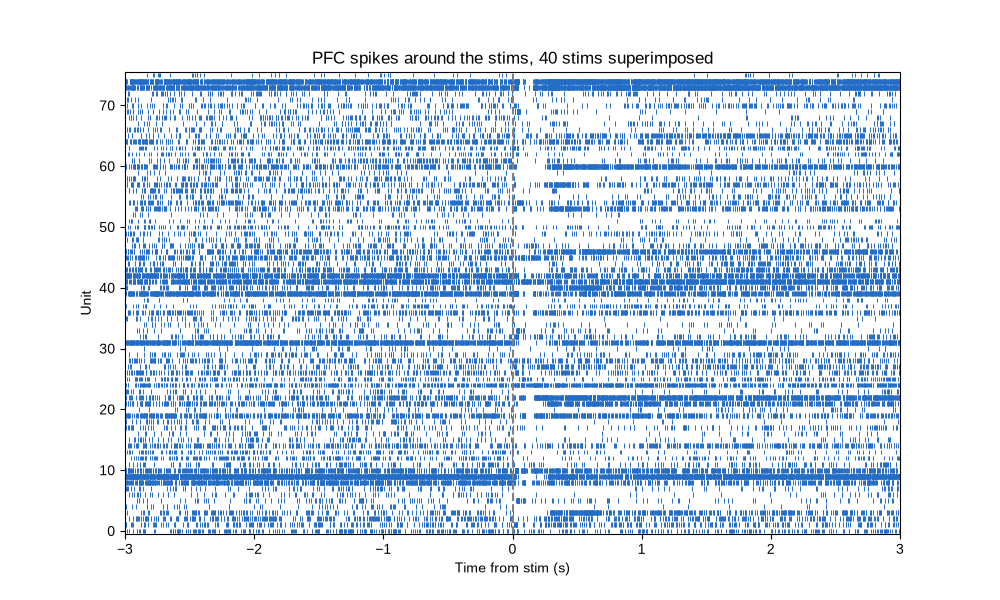

In [16]:


fig, ax = plt.subplots(figsize=(10, 6))
ax.eventplot(rel_by_unit, colors='#246DC6', linelengths=0.8, linewidths=0.7)   # one row per unit
ax.axvline(0, ls='--', color='gray')
ax.set_xlim(WIN)
ax.set_ylim(-0.5, len(unit_ids) - 0.5)
ax.set_xlabel('Time from stim (s)')
ax.set_ylabel('Unit')
ax.set_title(f'PFC spikes around the stims, {len(stim_starts)} stims superimposed')
